# PSet #3 · Notebook 03 — División, líneas base y modelos candidatos

**Orden**: 01 EDA → 02 Features → **03 Baselines/Candidatos** → 04 Tuning → 05 Selección.

**Reglas metodológicas**:
- La OBT es un corte transversal (no inventamos fechas de evento), por eso usamos **split estratificado 80/20** y `StratifiedKFold(5)` sobre entrenamiento.
- La imputación, OneHot y escalado se ajustan **dentro de `Pipeline`**, para cada fold.
- No se usa el hold-out para elegir modelos, ajustar umbrales ni crear features. Se reserva para el notebook 05.
- La métrica técnica principal es **Average Precision (AP)**, resumen no interpolado de la curva PR. También se registran recall, precisión y una **simulación de costo ilustrativa** (no es ROI comprobado).
- Se registran 2 baselines y 5 familias de candidatos en el servidor MLflow local, con parámetros, hash de la OBT, firma y ejemplo de entrada. 

In [1]:
from pathlib import Path
import json, os, subprocess, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from mlflow.models import infer_signature
import mlflow, mlflow.sklearn
from src.datos import leer_obt, variables_modelo, hash_snapshot, ORIGEN
from src.pipeline import crear_pipeline, crear_preprocesador, FeaturesDerivadas
from src.baselines import ReglaNegocio
from src.experimentos import evaluar_cv, entrenar_final_en_train

SEED = 42
OUT = Path('/workspace/docs'); OUT.mkdir(exist_ok=True, parents=True)
print('MLflow:', os.environ.get('MLFLOW_TRACKING_URI', '(sin variable)'))

MLflow: http://mlflow:5000


## A. ÚNICA separación train/test — sin exponer los registros de prueba a los experimentos

Guardamos las identidades de cada partición y el hash del snapshot. Ordenar por `CUSTOMER_ID` hace la separación reproducible si Snowflake devuelve las filas en otro orden. `INGESTED_AT` es metadato de ingesta, **no** fecha del evento de abandono.

In [2]:
df = leer_obt().sort_values('CUSTOMER_ID', kind='stable').reset_index(drop=True)
assert df['CUSTOMER_ID'].is_unique and df['CHURN_FLAG'].notna().all()
snapshot_hash = hash_snapshot(df)
X, y = variables_modelo(df)
assert set(['CUSTOMER_ID','INGESTED_AT','CHURN_FLAG']).isdisjoint(X.columns)
ids = df['CUSTOMER_ID']
idx_train, idx_test = train_test_split(
    np.arange(len(df)), test_size=0.20, random_state=SEED, stratify=y
)
idx_train = np.sort(idx_train); idx_test = np.sort(idx_test)
X_train, y_train = X.iloc[idx_train].copy(), y.iloc[idx_train].copy()
# NO se utilizan X_test/y_test hasta el notebook 05.
assert set(idx_train).isdisjoint(set(idx_test))
assert len(idx_train) + len(idx_test) == len(df)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(cv.split(X_train, y_train))

split_manifest = pd.DataFrame({'CUSTOMER_ID':ids, 'split':'test'})
split_manifest.loc[idx_train,'split'] = 'train'
split_manifest.to_csv(OUT/'split_train_test.csv', index=False)
info = {
 'origen': ORIGEN, 'hash_dataset':snapshot_hash, 'seed':SEED,
 'n_total':len(df), 'n_train':len(idx_train), 'n_test':len(idx_test),
 'estratificacion':True, 'cv':'StratifiedKFold(5) solo train',
 'target_train_rate':float(y_train.mean()),
 'nota_fecha':'INGESTED_AT es tiempo de carga, no fecha de abandono',
}
(OUT/'split_info.json').write_text(json.dumps(info,indent=2,ensure_ascii=False), encoding='utf-8')
print('Origen:', ORIGEN, 'Hash:', snapshot_hash)
print('Train:',len(idx_train),'| Test reservado:',len(idx_test),'| CV:',len(folds),'folds')
print('Churn en train:',f'{y_train.mean():.2%}')
print('Guardado:',OUT/'split_train_test.csv')

Origen: PSET2_CHURN.OBT.CUSTOMER_CHURN_OBT Hash: d394e39192c935f813db937647ea608341131d5b3021696fbbb186daff7043d3
Train: 5634 | Test reservado: 1409 | CV: 5 folds
Churn en train: 26.54%
Guardado: /workspace/docs/split_train_test.csv


## B. Preparación y baselines

- **Ingenua**: `DummyClassifier(strategy="prior")` con el mismo preprocessing de candidatos.
- **Negocio**: regla del PSet #1: `CONTRACT == "Month-to-month"` y `TENURE_MONTHS < 12`. La regla no aprende parámetros.

La regla da resultados binarios **no calibrados como probabilidades**, por lo que el AP de esta línea base será menos discriminante que el de modelos con scores continuos. La comparación sigue siendo un punto de referencia operativo.

Los valores económicos del escenario son **supuestos para sensibilidad**, NO importes medidos en la empresa.

In [3]:
# CAMBIAR si el negocio facilita valores reales o escenarios alternativos.
COSTO_CONTACTO = 5.0             # USD por cliente contactado (hipotético)
COSTO_ABANDONO = 120.0            # USD por abandono no evitado (hipotético)
EFICACIA_CONTACTO = 0.20         # proporción de TP realmente retenidos, hipótesis
# Estos costos NO se usan como prueba de mejora empresarial real.

experimentos = {
 'Baseline_Dummy': ('baseline','dummy', crear_pipeline(DummyClassifier(strategy='prior'))),
 'Baseline_Regla_PSet1': ('baseline','regla_negocio', ReglaNegocio(meses_limite=12)),
 'Candidato_Logistica': ('candidato','lineal_regularizado',crear_pipeline(LogisticRegression(max_iter=1000,random_state=SEED))),
 'Candidato_RandomForest': ('candidato','bagging',crear_pipeline(RandomForestClassifier(random_state=SEED,n_jobs=-1))),
 'Candidato_HistGradientBoosting': ('candidato','boosting',crear_pipeline(HistGradientBoostingClassifier(random_state=SEED))),
 'Candidato_MLP': ('candidato','red_neuronal',crear_pipeline(MLPClassifier(random_state=SEED,max_iter=200))),
 'Candidato_SVC': ('candidato','kernel_svm',crear_pipeline(SVC(probability=True,random_state=SEED))),
}
print('Experimentos preparados:',len(experimentos),'(2 baselines + 5 candidatos)')

Experimentos preparados: 7 (2 baselines + 5 candidatos)


## C. Tracking de los 7 experimentos en MLflow

Se entrenan las 7 propuestas con **exactamente los mismos folds, el mismo split y AP como métrica principal**. `max_iter=1000` para logística mejora la convergencia; `probability=True` en SVC permite usar sus scores en un análisis económico futuro. No se han ajustado hiperparámetros por rendimiento.

**Precaución:** puede tardar varios minutos, especialmente MLP y SVC. Cada modelo queda registrado en MLflow al terminar. No entrenamos con el conjunto de prueba.

In [4]:
TRACKING_URI = os.environ.get('MLFLOW_TRACKING_URI', 'http://mlflow:5000')
mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment('PSet3_Churn_Telco')
try:
    commit = subprocess.check_output(
        ['git','rev-parse','HEAD'], cwd='/workspace', stderr=subprocess.DEVNULL, text=True
    ).strip()
except Exception:
    commit = 'SIN_COMMIT_LOCAL'
    print('AVISO: no se detectó un commit de Git. Haz un commit para que las próximas corridas tengan SHA.')

filas_resultado=[]
for nombre, (fase,familia,est) in experimentos.items():
    print('Ejecutando:',nombre, flush=True)
    with mlflow.start_run(run_name=nombre) as run:
        mlflow.set_tags({
            'fase':fase, 'familia':familia, 'git_commit':commit,
            'origen':ORIGEN, 'hash_dataset':snapshot_hash,
            'nota':'snapshot transversal, sin seguimiento temporal'
        })
        mlflow.log_params({
            'seed':SEED, 'cv':'StratifiedKFold5', 'holdout_frac':0.20,
            'dataset_sha256':snapshot_hash,
            'fecha_snapshot':'sin_fecha_negocio',
            'filas_train':len(X_train), 'filas_test_reservadas':len(idx_test),
            'costo_contacto_hipotetico':COSTO_CONTACTO,
            'costo_abandono_hipotetico':COSTO_ABANDONO,
            'eficacia_contacto_hipotetica':EFICACIA_CONTACTO,
            'estimador':str(est.get_params(deep=False))[:500],
        })
        # Los parámetros internos del estimador son rastreables para reproducir cada corrida.
        modelo_interno=est.named_steps['modelo'] if hasattr(est,'named_steps') else est
        mlflow.log_params({f'hip_{k}':str(v)[:250] for k,v in modelo_interno.get_params(deep=False).items()})

        metrics=evaluar_cv(
            est,X_train,y_train,folds,
            costo_contacto=COSTO_CONTACTO,
            costo_abandono=COSTO_ABANDONO,
            eficacia_hipotetica=EFICACIA_CONTACTO
        )
        modelo_fit, segundos, train_ap = entrenar_final_en_train(est,X_train,y_train)
        metrics.update({
            'train_ap_full':train_ap,
            'gap_ap_train_vs_cv':train_ap-metrics['cv_ap_mean'],
            'fit_full_seconds':segundos,
        })
        mlflow.log_metrics(metrics)
        mlflow.log_dict(info,'split_info.json')
        ejemplo=X_train.head(5)
        firma=infer_signature(ejemplo, modelo_fit.predict(ejemplo))
        mlflow.sklearn.log_model(
            sk_model=modelo_fit, name='modelo',signature=firma,
            input_example=ejemplo,code_paths=['/workspace/src'],
        )
        filas_resultado.append({'nombre':nombre,'fase':fase,'familia':familia,
            'run_id':run.info.run_id,**metrics})
        print(f"  AP CV={metrics['cv_ap_mean']:.4f} ± {metrics['cv_ap_std']:.4f}"
              f" | AP train={train_ap:.4f} | costo simulado/100={metrics['cv_cost_per100_illustrative']:.2f}")

resultados=pd.DataFrame(filas_resultado).sort_values('cv_ap_mean',ascending=False)
resultados.to_csv(OUT/'resultados_candidatos.csv',index=False)
display(resultados[['nombre','fase','cv_ap_mean','cv_ap_std','train_ap_full',
                   'gap_ap_train_vs_cv','fit_full_seconds','cv_cost_per100_illustrative']].round(4))
print('Guardado: docs/resultados_candidatos.csv')

2026/11/19 03:47:15 INFO mlflow.tracking.fluent: Experiment with name 'PSet3_Churn_Telco' does not exist. Creating a new experiment.


AVISO: no se detectó un commit de Git. Haz un commit para que las próximas corridas tengan SHA.
Ejecutando: Baseline_Dummy


/usr/local/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.11/site-packages/sklearn/metrics/_clas

  AP CV=0.2654 ± 0.0001 | AP train=0.2654 | costo simulado/100=3184.24
🏃 View run Baseline_Dummy at: http://mlflow:5000/#/experiments/1/runs/3630872085c1443994eee2b9ba822a9b
🧪 View experiment at: http://mlflow:5000/#/experiments/1
Ejecutando: Baseline_Regla_PSet1


/usr/local/lib/python3.11/site-packages/mlflow/types/utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


  AP CV=0.4022 ± 0.0071 | AP train=0.4021 | costo simulado/100=2981.13
🏃 View run Baseline_Regla_PSet1 at: http://mlflow:5000/#/experiments/1/runs/4be082863e2a4196a2c2ae896fdc7066
🧪 View experiment at: http://mlflow:5000/#/experiments/1
Ejecutando: Candidato_Logistica


... (8 outputs left out)

/usr/local/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedC

  AP CV=0.6342 ± 0.0166 | AP train=0.7030 | costo simulado/100=2971.57
🏃 View run Candidato_SVC at: http://mlflow:5000/#/experiments/1/runs/baa38c24d9cc49409d5bcec14a0dc53b
🧪 View experiment at: http://mlflow:5000/#/experiments/1


,nombre,fase,cv_ap_mean,cv_ap_std,train_ap_full,gap_ap_train_vs_cv,fit_full_seconds,cv_cost_per100_illustrative
2,Candidato_Logistica,candidato,0.6531,0.0116,0.6605,0.0074,0.0575,2949.5563
4,Candidato_HistGradientBoosting,candidato,0.6413,0.0283,0.8602,0.2189,0.2352,2956.1590
6,Candidato_SVC,candidato,0.6342,0.0166,0.7030,0.0688,2.1306,2971.5655
3,Candidato_RandomForest,candidato,0.6105,0.0175,0.9998,0.3893,0.2506,2973.6599
5,Candidato_MLP,candidato,0.5918,0.0224,0.8122,0.2204,2.1754,2970.7668
1,Baseline_Regla_PSet1,baseline,0.4022,0.0071,0.4021,-0.0001,0.0000,2981.1324
0,Baseline_Dummy,baseline,0.2654,0.0001,0.2654,-0.0000,0.0386,3184.2386


Guardado: docs/resultados_candidatos.csv


## D. Evidencia gráfica y próximos pasos

Si el `gap_ap_train_vs_cv` es grande frente a `cv_ap_std`, existe señal de posible sobreajuste. El **tuning de los tres mejores candidatos** se hará solo en entrenamiento en el notebook 04; allí se requieren **30 configuraciones por modelo** y corridas anidadas. El **hold-out permanece intacto** hasta el notebook 05.

**Nota sobre LLM:** el PSet también exige una prueba de prompting. Se documentará como un experimento separado, porque el CSV no incluye conversaciones o textos libres que favorezcan clasificación mediante prompts. No inventaremos métricas para ese ensayo.

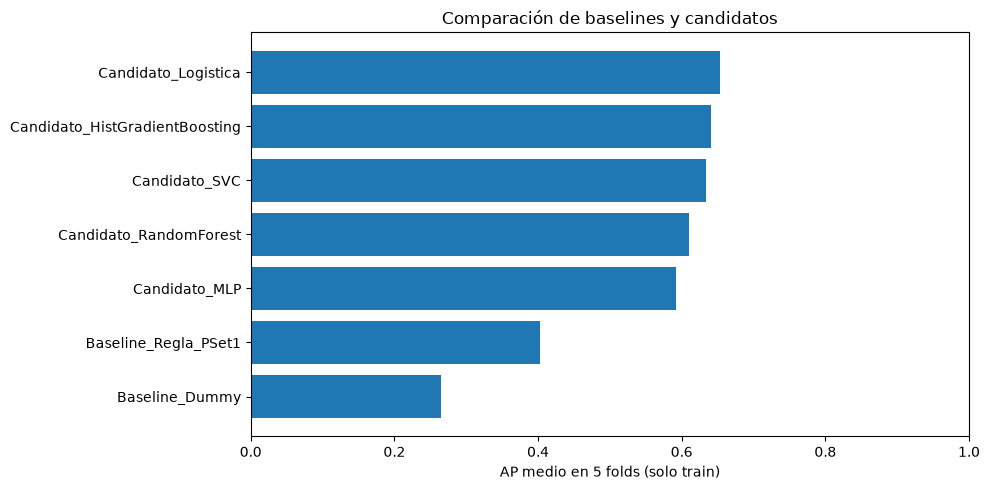

Tres candidatos para probar 30 configuraciones c/u (sin tocar el test):


,nombre,cv_ap_mean,cv_ap_std,gap_ap_train_vs_cv
2,Candidato_Logistica,0.653105,0.011636,0.007373
4,Candidato_HistGradientBoosting,0.641311,0.028263,0.218923
6,Candidato_SVC,0.634204,0.016595,0.068821


Revisa en el navegador http://localhost:5000 (experimento PSet3_Churn_Telco)


In [5]:
orden=resultados.sort_values('cv_ap_mean')
fig,ax=plt.subplots(figsize=(10,5))
ax.barh(orden['nombre'],orden['cv_ap_mean'])
ax.set(xlabel='AP medio en 5 folds (solo train)',title='Comparación de baselines y candidatos')
ax.set_xlim(0,1)
plt.tight_layout()
plt.savefig(OUT/'candidatos_cv_ap.png',dpi=150)
plt.show()

candidatos=resultados.query("fase == 'candidato'").sort_values('cv_ap_mean',ascending=False)
print('Tres candidatos para probar 30 configuraciones c/u (sin tocar el test):')
display(candidatos[['nombre','cv_ap_mean','cv_ap_std','gap_ap_train_vs_cv']].head(3))
print('Revisa en el navegador http://localhost:5000 (experimento PSet3_Churn_Telco)')